<a href="https://colab.research.google.com/github/wsteve16/Intro-to-Machine-Learning/blob/main/ML_HW_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

linear: accuracy=0.9561 precision=0.9318 recall=0.9535 f1=0.9425
poly: accuracy=0.8684 precision=1.0000 recall=0.6512 f1=0.7887
rbf: accuracy=0.9825 precision=1.0000 recall=0.9535 f1=0.9762
logistic regression (HW3): accuracy=0.9825 precision=0.9767 recall=0.9767 f1=0.9767


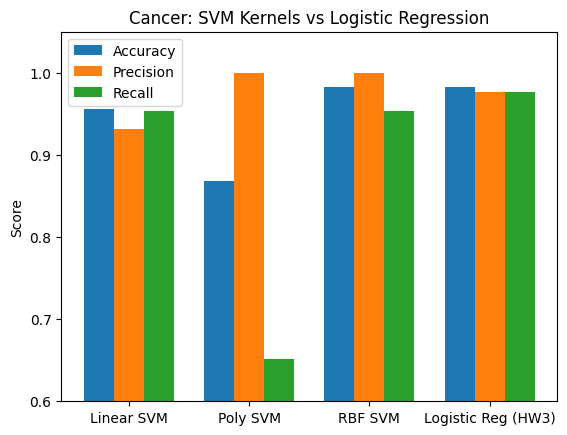

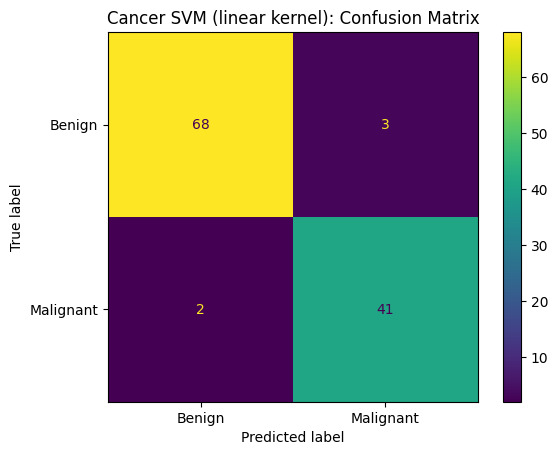

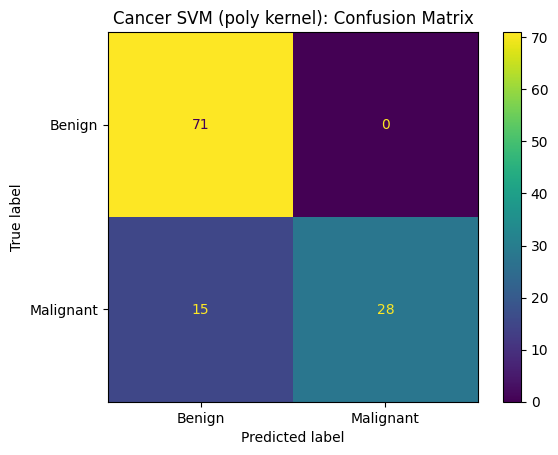

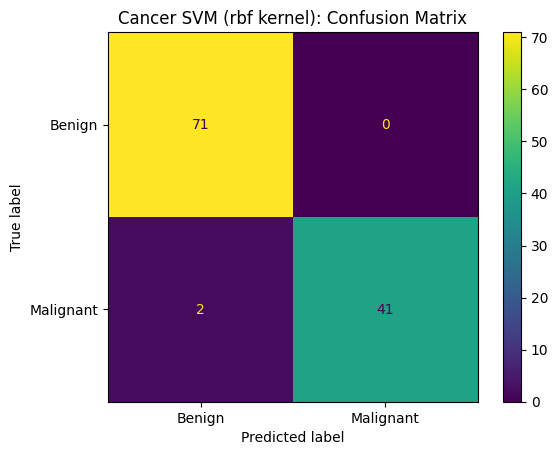

SVR Linear: val MSE = 1.9311e+12, val R2 = 0.6180
SVR Polynomial: val MSE = 2.4918e+12, val R2 = 0.5070
SVR RBF: val MSE = 1.9059e+12, val R2 = 0.6229
Ridge linear regression: val MSE = 1.8014e+12, val R2 = 0.6436


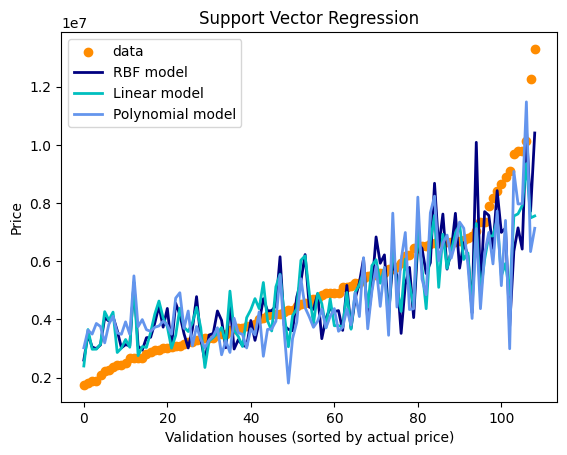

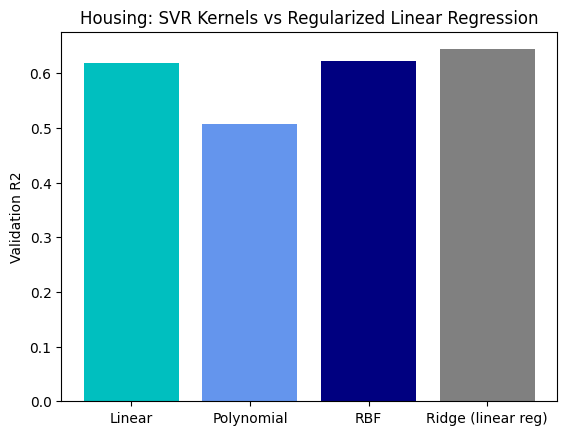

In [3]:
#Will Stevens
#Intro to ML HW 4
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

housing_path = 'Housing.csv'
housing_df = pd.read_csv(housing_path)

cancer_path  = 'Cancer.csv'
cancer_df= pd.read_csv(cancer_path)

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, SVR
from sklearn.linear_model import Ridge
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              mean_squared_error, r2_score, ConfusionMatrixDisplay)

#Q1: Use the cancer dataset to build an SVM classifier to classify the type of cancer (Malignant vs. benign).
#Plot your classification accuracy, precision, and recall. Explore different kernel tricks to capture non-linearities within your data.
#Plot the results and compare the accuracies for different kernels.
#Compare your results against the logistic regression that you have done in HW 3.

cancer_df = cancer_df.drop(columns=['id', 'Unnamed: 32'])
y_c = cancer_df['diagnosis'].map({'M': 1, 'B': 0}).values
X_c = cancer_df.drop(columns=['diagnosis']).values.astype(float)

#80/20 split/ standardize using TRAIN stats
X_train_c, X_val_c, y_train_c, y_val_c = train_test_split(X_c, y_c, test_size=0.2, random_state=42)
scaler_c = StandardScaler()
X_train_c = scaler_c.fit_transform(X_train_c)
X_val_c = scaler_c.transform(X_val_c)

#try 3 kernels: linear, polynomial, rbf
kernels = ['linear', 'poly', 'rbf']
results_c = {}
preds_c = {}
for k in kernels:
    svm = SVC(kernel=k)
    svm.fit(X_train_c, y_train_c)
    pred = svm.predict(X_val_c)
    preds_c[k] = pred
    results_c[k] = [accuracy_score(y_val_c, pred), precision_score(y_val_c, pred),
                    recall_score(y_val_c, pred), f1_score(y_val_c, pred)]
    print(f"{k}: accuracy={results_c[k][0]:.4f} precision={results_c[k][1]:.4f} "
          f"recall={results_c[k][2]:.4f} f1={results_c[k][3]:.4f}")


# bar chart of accuracy, precision, and recall for each kernel
labels = ['Linear SVM', 'Poly SVM', 'RBF SVM', 'Logistic Reg (HW3)']
metric_names = ['Accuracy', 'Precision', 'Recall']
all_results = [results_c[k][:3] for k in kernels] + [logreg_results[:3]]
x = np.arange(len(labels))
width = 0.25
for i, name in enumerate(metric_names):
    plt.bar(x + (i - 1) * width, [r[i] for r in all_results], width, label=name)
plt.xticks(x, labels)
plt.ylim(0.6, 1.05)
plt.ylabel('Score')
plt.title('Cancer: SVM Kernels vs Logistic Regression')
plt.legend()
plt.show()

#confusion matrix for each kernel
for k in kernels:
    ConfusionMatrixDisplay.from_predictions(y_val_c, preds_c[k], display_labels=['Benign', 'Malignant'])
    plt.title(f'Cancer SVM ({k} kernel): Confusion Matrix')
    plt.show()

#Q2: Develop a SVR regression model that predicts housing price based on the following input variables:
#Area, bedrooms, bathrooms, stories, mainroad, guestroom, basement, hotwaterheating, airconditioning, parking, prefarea
#Plot your regression model for SVR similar to the sample code provided on the course GitHub.
#Compare your results against linear regression with regularization loss that you already did in HW1.
#Explore different kernel tricks to capture non-linearities within your data. Plot the results and compare the accuracies for different kernels.

#convert yes/no columns to 1/0
binary_cols = ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea']
for col in binary_cols:
    housing_df[col] = housing_df[col].map({'yes': 1, 'no': 0})

features = ['area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom',
            'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea']
X_h = housing_df[features].values.astype(float)
y_h = housing_df['price'].values.astype(float)

#80/20 split / standardize inputs using TRAIN stats only
X_train_h, X_val_h, y_train_h, y_val_h = train_test_split(X_h, y_h, test_size=0.2, random_state=42)
scaler_h = StandardScaler()
X_train_h = scaler_h.fit_transform(X_train_h)
X_val_h = scaler_h.transform(X_val_h)

#SVR is sensitive to the scale of the target so the
#price is standardized for training and converted back for the results
scaler_y = StandardScaler()
y_train_s = scaler_y.fit_transform(y_train_h.reshape(-1, 1)).ravel()

#3 kernels: linear, polynomial, rbf
svr_models = {
    'Linear': SVR(kernel='linear', C=10),
    'Polynomial': SVR(kernel='poly', degree=2, C=10),
    'RBF': SVR(kernel='rbf', C=10),
}
preds_h = {}
results_h = {}
for name, svr in svr_models.items():
    svr.fit(X_train_h, y_train_s)
    pred = scaler_y.inverse_transform(svr.predict(X_val_h).reshape(-1, 1)).ravel()
    preds_h[name] = pred
    results_h[name] = [mean_squared_error(y_val_h, pred), r2_score(y_val_h, pred)]
    print(f"SVR {name}: val MSE = {results_h[name][0]:.4e}, val R2 = {results_h[name][1]:.4f}")

#regularized linear regression for comparison
ridge = Ridge(alpha=1)
ridge.fit(X_train_h, y_train_h)
ridge_pred = ridge.predict(X_val_h)
ridge_mse = mean_squared_error(y_val_h, ridge_pred)
ridge_r2 = r2_score(y_val_h, ridge_pred)
print(f"Ridge linear regression: val MSE = {ridge_mse:.4e}, val R2 = {ridge_r2:.4f}")

#plot like the SVR sample
order = np.argsort(y_val_h)
lw = 2
plt.scatter(range(len(order)), y_val_h[order], color='darkorange', label='data')
plt.plot(preds_h['RBF'][order], color='navy', lw=lw, label='RBF model')
plt.plot(preds_h['Linear'][order], color='c', lw=lw, label='Linear model')
plt.plot(preds_h['Polynomial'][order], color='cornflowerblue', lw=lw, label='Polynomial model')
plt.xlabel('Validation houses (sorted by actual price)')
plt.ylabel('Price')
plt.title('Support Vector Regression')
plt.legend()
plt.show()

#compare R2 across kernels and against the regularized linear regression
names = list(results_h.keys()) + ['Ridge (linear reg)']
r2_values = [results_h[n][1] for n in results_h] + [ridge_r2]
plt.bar(names, r2_values, color=['c', 'cornflowerblue', 'navy', 'gray'])
plt.ylabel('Validation R2')
plt.title('Housing: SVR Kernels vs Regularized Linear Regression')
plt.show()
